# Pairwise AUC-Matched Commit-Time Comparisons Across Brain Regions

**Dataset:** `matched_units_<A>_<B>_nTc_results_paper_compare.csv` files  
**Animals:** A324, A327, C211 (19 sessions total)

---

## Overview

This notebook uses the **pairwise AUC-matched** nTc CSVs to build lead/lag
heatmaps across brain regions. Each CSV contains commit times for a single
pair of regions, computed from AUC-matched neuron subsets.

### Sign convention

Every pairwise comparison is labelled **Region A − Region B**.
- **Negative** Δ → Region A commits *earlier* (leads).
- **Positive** Δ → Region A commits *later* (lags).

### Display conventions

- All heatmaps use the **same fixed region order** and **same colour scale**.
- **Black cells** indicate the diagonal or pairs with no available data.
- Region tick labels are **coloured by brain region** and rendered in bold.


---\n## 0 — Imports & Settings

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from itertools import combinations
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.tools.sm_exceptions import ConvergenceWarning
import warnings, os, glob, re
from pathlib import Path

warnings.filterwarnings('ignore', category=ConvergenceWarning)
warnings.filterwarnings('ignore', message='.*covariance.*singular.*', module='statsmodels')
warnings.filterwarnings('ignore', message='.*covariance matrix.*', module='statsmodels')
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=RuntimeWarning)

# ---------- Font setup ----------
_FONT_CANDIDATES = ['Helvetica LT Pro', 'Helvetica', 'Helvetica Neue', 'Arial']
_FONT_NAME = 'sans-serif'
for _fc in _FONT_CANDIDATES:
    if any(_fc.lower() in f.lower() for f in fm.findSystemFonts()):
        _FONT_NAME = _fc
        break
    try:
        fp = fm.FontProperties(family=_fc)
        if _fc.lower() in fp.get_name().lower():
            _FONT_NAME = _fc
            break
    except Exception:
        pass
print(f'Using font: {_FONT_NAME}')

# ---------- Plot aesthetics ----------
plt.rcParams.update({
    'figure.dpi': 150,
    'font.family': _FONT_NAME,
    'font.size': 14,
    'axes.titlesize': 16,
    'axes.titleweight': 'bold',
    'axes.labelsize': 14,
    'xtick.labelsize': 13,
    'ytick.labelsize': 13,
    'legend.fontsize': 12,
    'figure.titlesize': 18,
})

# ---------- Fixed region display order ----------
REGIONS = ['M1', 'ADS', 'dmFC', 'MGB', 'mPFC', 'TS', 'HPC', 'S1', 'BLA', 'NAc']

# ---------- Region colours ----------
REGION_COLORS = {
    'ADS':  '#d62728',
    'M1':   '#1f77b4',
    'dmFC': '#ff7f0e',
    'MGB':  '#9467bd',
    'mPFC': '#bcbd22',
    'TS':   '#2ca02c',
    'HPC':  '#17becf',
    'NAc':  '#e377c2',
    'S1':   '#8c564b',
    'BLA':  '#7f7f7f',
}

# ---------- Figure output directory ----------
FIG_DIR = Path('.') / 'figures_pairwise_aucmatched'
FIG_DIR.mkdir(exist_ok=True)
print(f'Figures will be saved to: {FIG_DIR.resolve()}/')


findfont: Font family ['Helvetica LT Pro'] not found. Falling back to DejaVu Sans.


Using font: Helvetica
Figures will be saved to: /Users/jc2988/Documents/GitHub/uberphys/julie/analyses/forBCLpaper/figures_pairwise_aucmatched/


---
## 1 — Auto-Discover & Load Pairwise AUC-Matched CSVs

Each CSV is named `matched_units_<RegionA>_<RegionB>_nTc_results_paper_compare.csv`.
The code scans the notebook's directory, extracts the two region names from each
filename, and loads the `our_committime_s_<Region>` columns.

Relative commit times are computed as `our_committime_s_<Region> − stereoclick_time_s`.


In [2]:
# ---------- Auto-discover CSV files ----------
csv_pattern = 'matched_units_*_nTc_results_paper_compare.csv'
csv_files = sorted(glob.glob(csv_pattern))

if not csv_files:
    raise FileNotFoundError(
        f'No files matching {csv_pattern} found in {os.getcwd()}.\n'
        f'Place the notebook in the same folder as the pairwise CSVs.'
    )

print(f'Found {len(csv_files)} pairwise CSV files:\n')

pair_data = {}   # (regionA, regionB) sorted tuple -> DataFrame

for fpath in csv_files:
    raw = pd.read_csv(fpath)
    pname = raw['pair_name'].iloc[0]
    match = re.match(r'matched_units_(.+?)_(.+)', pname)
    if not match:
        print(f'  WARNING: cannot parse pair_name "{pname}" in {fpath} — skipping')
        continue

    regionA, regionB = match.group(1), match.group(2)
    colA = f'our_committime_s_{regionA}'
    colB = f'our_committime_s_{regionB}'

    if colA not in raw.columns or colB not in raw.columns:
        print(f'  WARNING: expected columns {colA}, {colB} not found — skipping')
        continue

    sub = raw[['recording_id', 'stereoclick_time_s', colA, colB]].copy()
    sub['animal'] = sub['recording_id'].str.extract(r'^([A-Z]\d+)')
    sub[f'rel_{regionA}'] = sub[colA] - sub['stereoclick_time_s']
    sub[f'rel_{regionB}'] = sub[colB] - sub['stereoclick_time_s']

    pair_key = tuple(sorted([regionA, regionB]))
    pair_data[pair_key] = sub

    n_both = sub[[f'rel_{regionA}', f'rel_{regionB}']].dropna().shape[0]
    print(f'  {regionA:>5s} – {regionB:<5s} : {len(sub):5d} rows, '
          f'{n_both:4d} with both valid  ({os.path.basename(fpath)})')

print(f'\nTotal region pairs loaded: {len(pair_data)}')

# ---------- Determine animals and per-animal region availability ----------
all_animals = set()
for sub in pair_data.values():
    all_animals.update(sub['animal'].dropna().unique())
animals = sorted(all_animals)

animal_regions = {}
for animal in animals:
    regs = set()
    for (rA, rB), sub in pair_data.items():
        asub = sub[sub['animal'] == animal]
        if asub[f'rel_{rA}'].notna().any():
            regs.add(rA)
        if asub[f'rel_{rB}'].notna().any():
            regs.add(rB)
    animal_regions[animal] = [r for r in REGIONS if r in regs]

print(f'\nAnimals: {animals}')
for a in animals:
    print(f'  {a}: {animal_regions[a]}')


Found 45 pairwise CSV files:

    ADS – BLA   :  5050 rows,  532 with both valid  (matched_units_ADS_BLA_nTc_results_paper_compare.csv)
    ADS – HPC   :  8705 rows,  748 with both valid  (matched_units_ADS_HPC_nTc_results_paper_compare.csv)
    ADS – M1    :  9907 rows, 1850 with both valid  (matched_units_ADS_M1_nTc_results_paper_compare.csv)
    ADS – MGB   :  9907 rows, 1096 with both valid  (matched_units_ADS_MGB_nTc_results_paper_compare.csv)
    ADS – NAc   :  9907 rows,  565 with both valid  (matched_units_ADS_NAc_nTc_results_paper_compare.csv)
    ADS – S1    :  5412 rows,  398 with both valid  (matched_units_ADS_S1_nTc_results_paper_compare.csv)
    ADS – TS    :  7829 rows,  920 with both valid  (matched_units_ADS_TS_nTc_results_paper_compare.csv)
    ADS – dmFC  :  9907 rows, 1050 with both valid  (matched_units_ADS_dmFC_nTc_results_paper_compare.csv)
    ADS – mPFC  :  9907 rows,  740 with both valid  (matched_units_ADS_mPFC_nTc_results_paper_compare.csv)
    HPC – BLA   :

---
## 2 — Helper Functions


In [3]:
def _sig_label(p):
    """Return a significance label string from a p-value."""
    if p is None or np.isnan(p):
        return ''
    if p < 0.001: return '***'
    if p < 0.01:  return '**'
    if p < 0.05:  return '*'
    return 'n.s.'


def get_pair_diffs(pair_data, animal, regionA, regionB):
    """
    Get trial-level differences (A − B) for one animal from the pairwise CSV.
    Returns a DataFrame with columns ['recording_id', 'diff'], or None.
    """
    pair_key = tuple(sorted([regionA, regionB]))
    if pair_key not in pair_data:
        return None

    df = pair_data[pair_key]
    asub = df[df['animal'] == animal].copy()
    colA, colB = f'rel_{regionA}', f'rel_{regionB}'
    if colA not in asub.columns or colB not in asub.columns:
        return None

    valid = asub.dropna(subset=[colA, colB]).copy()
    if len(valid) == 0:
        return None

    valid['diff'] = valid[colA] - valid[colB]
    return valid[['recording_id', 'diff']]


def pairwise_animal_stats(pair_data, animal, regionA, regionB):
    """
    Within one animal: LMM test for (A − B).
    Returns: grand_mean, grand_sem, z_or_t, p_val, n_trials, method_used
    """
    sub = get_pair_diffs(pair_data, animal, regionA, regionB)
    if sub is None or len(sub) == 0:
        return np.nan, np.nan, np.nan, np.nan, 0, 'n/a'

    n_trials = len(sub)
    n_sessions = sub['recording_id'].nunique()
    sess_means = sub.groupby('recording_id')['diff'].mean()
    grand_mean = sess_means.mean()
    grand_sem = (sess_means.std(ddof=1) / np.sqrt(len(sess_means))
                 if len(sess_means) > 1 else np.nan)

    if n_trials < 2:
        return grand_mean, grand_sem, np.nan, np.nan, n_trials, 'n/a'

    if n_sessions >= 2:
        try:
            model = smf.mixedlm('diff ~ 1', data=sub, groups=sub['recording_id'])
            fit = model.fit(reml=True)
            if fit.bse['Intercept'] > 10 * sub['diff'].std():
                raise ValueError('Degenerate')
            return (grand_mean, grand_sem, fit.tvalues['Intercept'],
                    fit.pvalues['Intercept'], n_trials, 'LMM')
        except Exception:
            t_stat, p_val = stats.ttest_1samp(sub['diff'].values, 0)
            return grand_mean, grand_sem, t_stat, p_val, n_trials, 't-test (LMM failed)'
    else:
        t_stat, p_val = stats.ttest_1samp(sub['diff'].values, 0)
        return grand_mean, grand_sem, t_stat, p_val, n_trials, 't-test (1 session)'



def color_ticklabels(ax, regions, axis='both'):
    """Apply region-specific colours and bold font to tick labels."""
    if axis in ('both', 'x'):
        for lbl in ax.get_xticklabels():
            r = lbl.get_text()
            if r in REGION_COLORS:
                lbl.set_color(REGION_COLORS[r])
            lbl.set_fontweight('bold')
            lbl.set_fontfamily(_FONT_NAME)
    if axis in ('both', 'y'):
        for lbl in ax.get_yticklabels():
            r = lbl.get_text()
            if r in REGION_COLORS:
                lbl.set_color(REGION_COLORS[r])
            lbl.set_fontweight('bold')
            lbl.set_fontfamily(_FONT_NAME)


---
## 3 — Compute Shared Colour Scale

A single `GLOBAL_VMAX` is computed across **all per-animal and combined**
pairwise differences so that every heatmap uses the same colour range.


In [4]:
_all_abs = []

# Per-animal values
for animal in animals:
    avail = set(animal_regions[animal])
    for rA, rB in combinations(REGIONS, 2):
        if rA in avail and rB in avail:
            gm, _, _, _, n_tr, _ = pairwise_animal_stats(pair_data, animal, rA, rB)
            if not np.isnan(gm) and n_tr > 0:
                _all_abs.append(abs(gm * 1000))

# Combined values (grand mean of per-animal means)
for rA, rB in combinations(REGIONS, 2):
    animal_means = []
    for animal in animals:
        sub = get_pair_diffs(pair_data, animal, rA, rB)
        if sub is not None and len(sub) > 0:
            sess_means = sub.groupby('recording_id')['diff'].mean()
            animal_means.append(sess_means.mean())
    if animal_means:
        gm = np.mean(animal_means)
        if not np.isnan(gm):
            _all_abs.append(abs(gm * 1000))

GLOBAL_VMAX = max(max(_all_abs), 50) if _all_abs else 250
GLOBAL_VMAX = min(GLOBAL_VMAX, 300)
print(f'GLOBAL_VMAX = {GLOBAL_VMAX:.1f} ms  (shared across all heatmaps)')
del _all_abs


GLOBAL_VMAX = 226.5 ms  (shared across all heatmaps)


---
## 4 — Per-Animal Grand-Mean Heatmaps + Within-Animal LMM

For each animal, a 10×10 heatmap in the fixed region order. Each off-diagonal
cell with data shows the grand-mean Δ (ms) and significance stars.
**Black cells** = diagonal or no data for that pair.

Statistical model: `diff ~ 1 + (1 | session)` [REML].


/var/folders/5k/pff9ts0j0jn2nmnnxqwrk_zr0000gq/T/ipykernel_77657/3247643185.py:88: UserWarning: Glyph 8594 (\N{RIGHTWARDS ARROW}) missing from font(s) Helvetica.
  fig.tight_layout()
/var/folders/5k/pff9ts0j0jn2nmnnxqwrk_zr0000gq/T/ipykernel_77657/3247643185.py:89: UserWarning: Glyph 8594 (\N{RIGHTWARDS ARROW}) missing from font(s) Helvetica.
  fig.savefig(FIG_DIR / f'animal_heatmap_aucmatched_{animal}.svg',
/opt/miniconda3/envs/bl_pipeline_python_env/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8594 (\N{RIGHTWARDS ARROW}) missing from font(s) Helvetica.
  fig.canvas.print_figure(bytes_io, **kw)


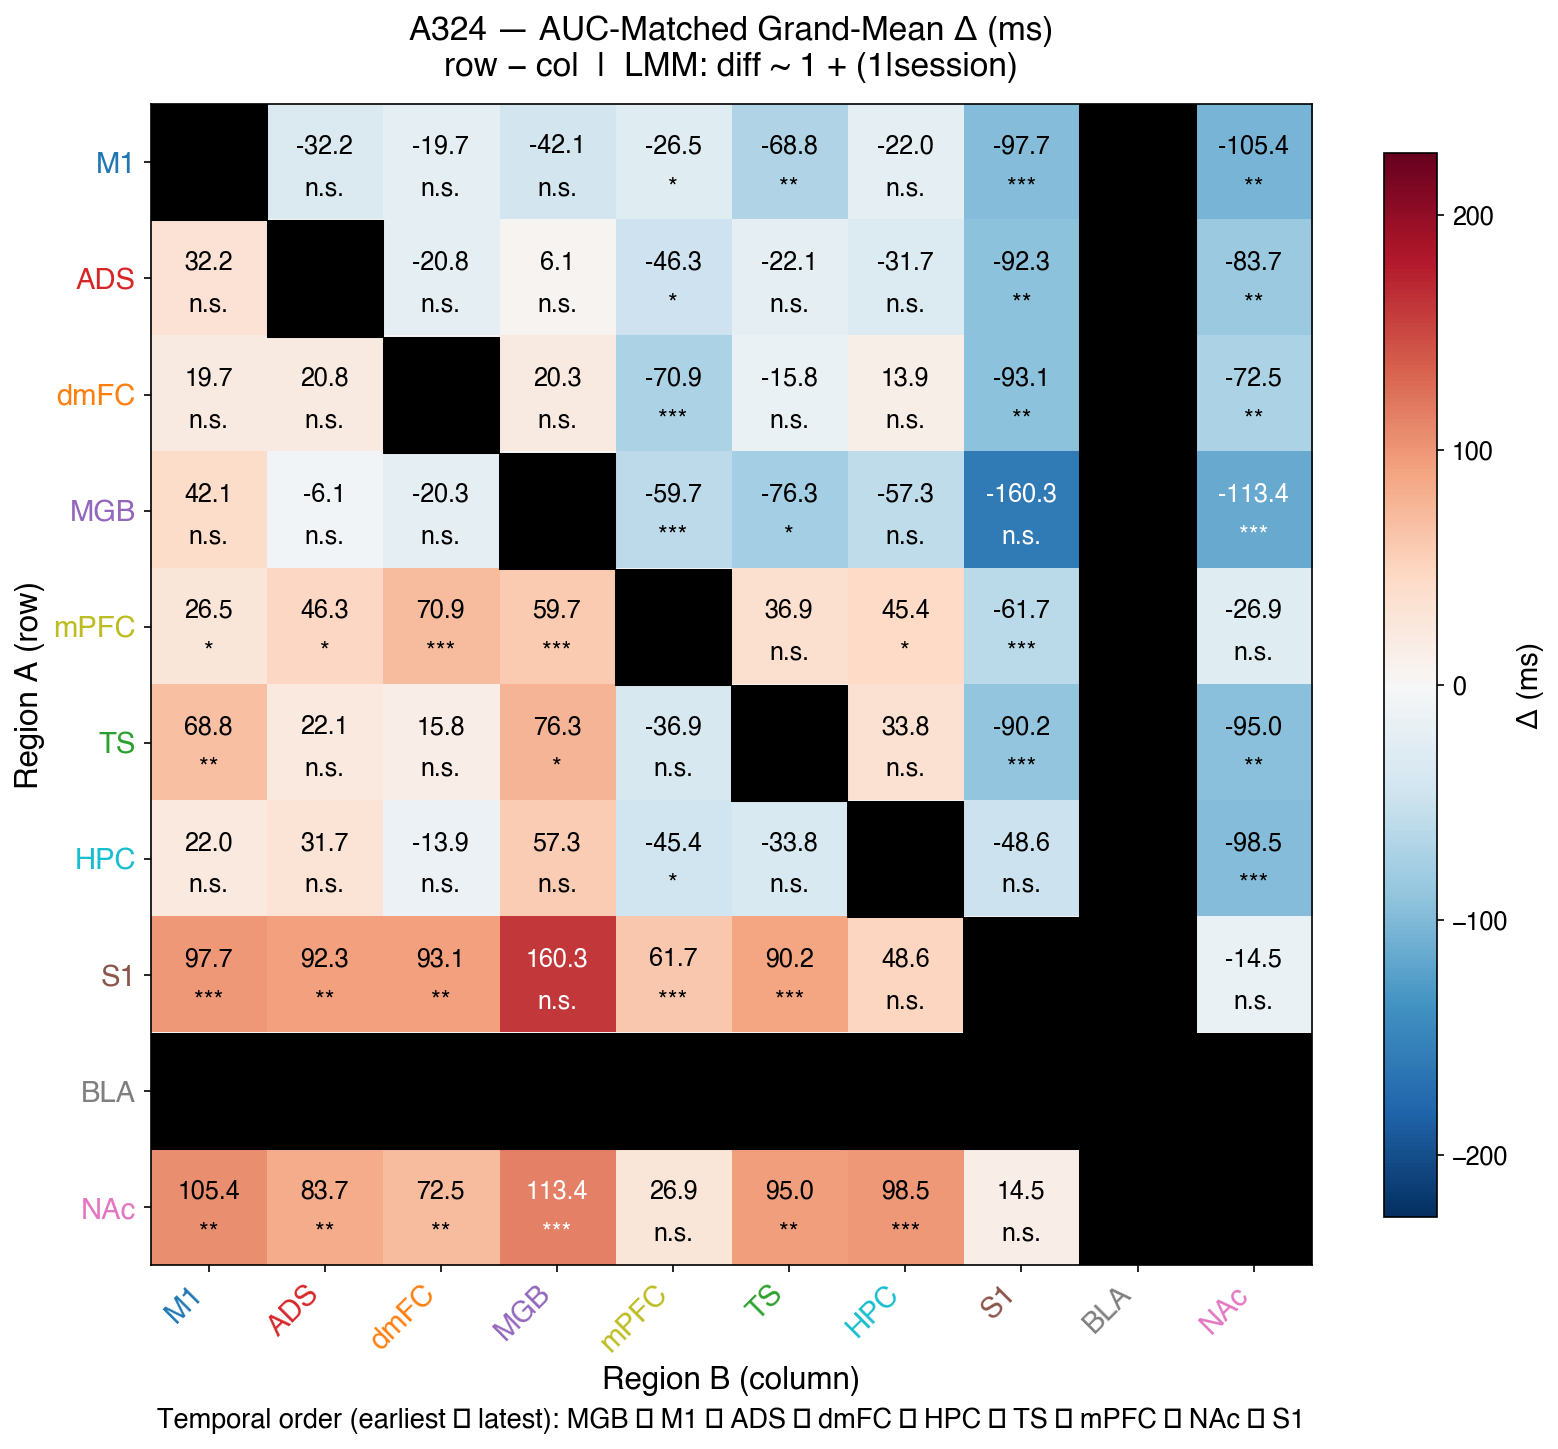

  A324 order: MGB → M1 → ADS → dmFC → HPC → TS → mPFC → NAc → S1


/var/folders/5k/pff9ts0j0jn2nmnnxqwrk_zr0000gq/T/ipykernel_77657/3247643185.py:88: UserWarning: Glyph 8594 (\N{RIGHTWARDS ARROW}) missing from font(s) Helvetica.
  fig.tight_layout()
/var/folders/5k/pff9ts0j0jn2nmnnxqwrk_zr0000gq/T/ipykernel_77657/3247643185.py:89: UserWarning: Glyph 8594 (\N{RIGHTWARDS ARROW}) missing from font(s) Helvetica.
  fig.savefig(FIG_DIR / f'animal_heatmap_aucmatched_{animal}.svg',
/opt/miniconda3/envs/bl_pipeline_python_env/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8594 (\N{RIGHTWARDS ARROW}) missing from font(s) Helvetica.
  fig.canvas.print_figure(bytes_io, **kw)


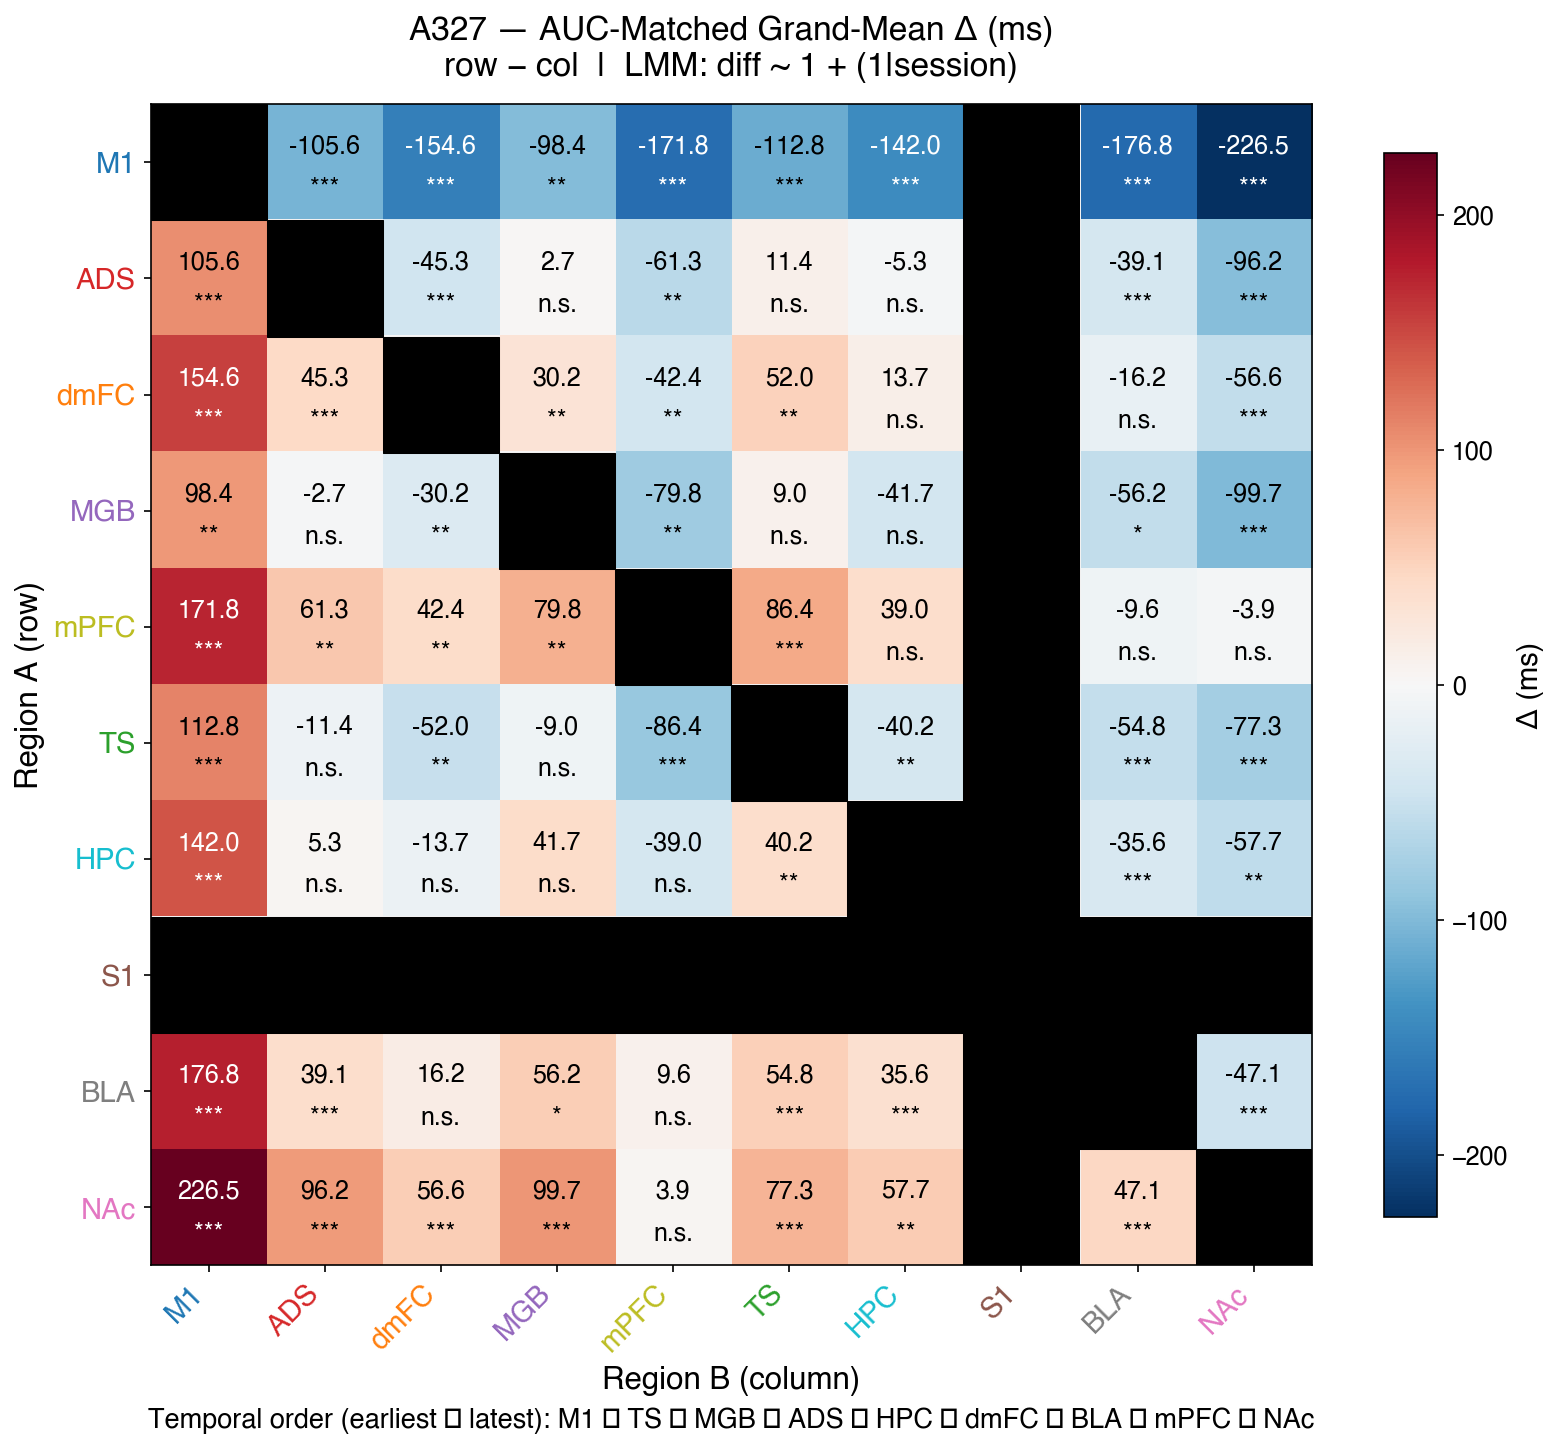

  A327 order: M1 → TS → MGB → ADS → HPC → dmFC → BLA → mPFC → NAc


/var/folders/5k/pff9ts0j0jn2nmnnxqwrk_zr0000gq/T/ipykernel_77657/3247643185.py:88: UserWarning: Glyph 8594 (\N{RIGHTWARDS ARROW}) missing from font(s) Helvetica.
  fig.tight_layout()
/var/folders/5k/pff9ts0j0jn2nmnnxqwrk_zr0000gq/T/ipykernel_77657/3247643185.py:89: UserWarning: Glyph 8594 (\N{RIGHTWARDS ARROW}) missing from font(s) Helvetica.
  fig.savefig(FIG_DIR / f'animal_heatmap_aucmatched_{animal}.svg',
/opt/miniconda3/envs/bl_pipeline_python_env/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8594 (\N{RIGHTWARDS ARROW}) missing from font(s) Helvetica.
  fig.canvas.print_figure(bytes_io, **kw)


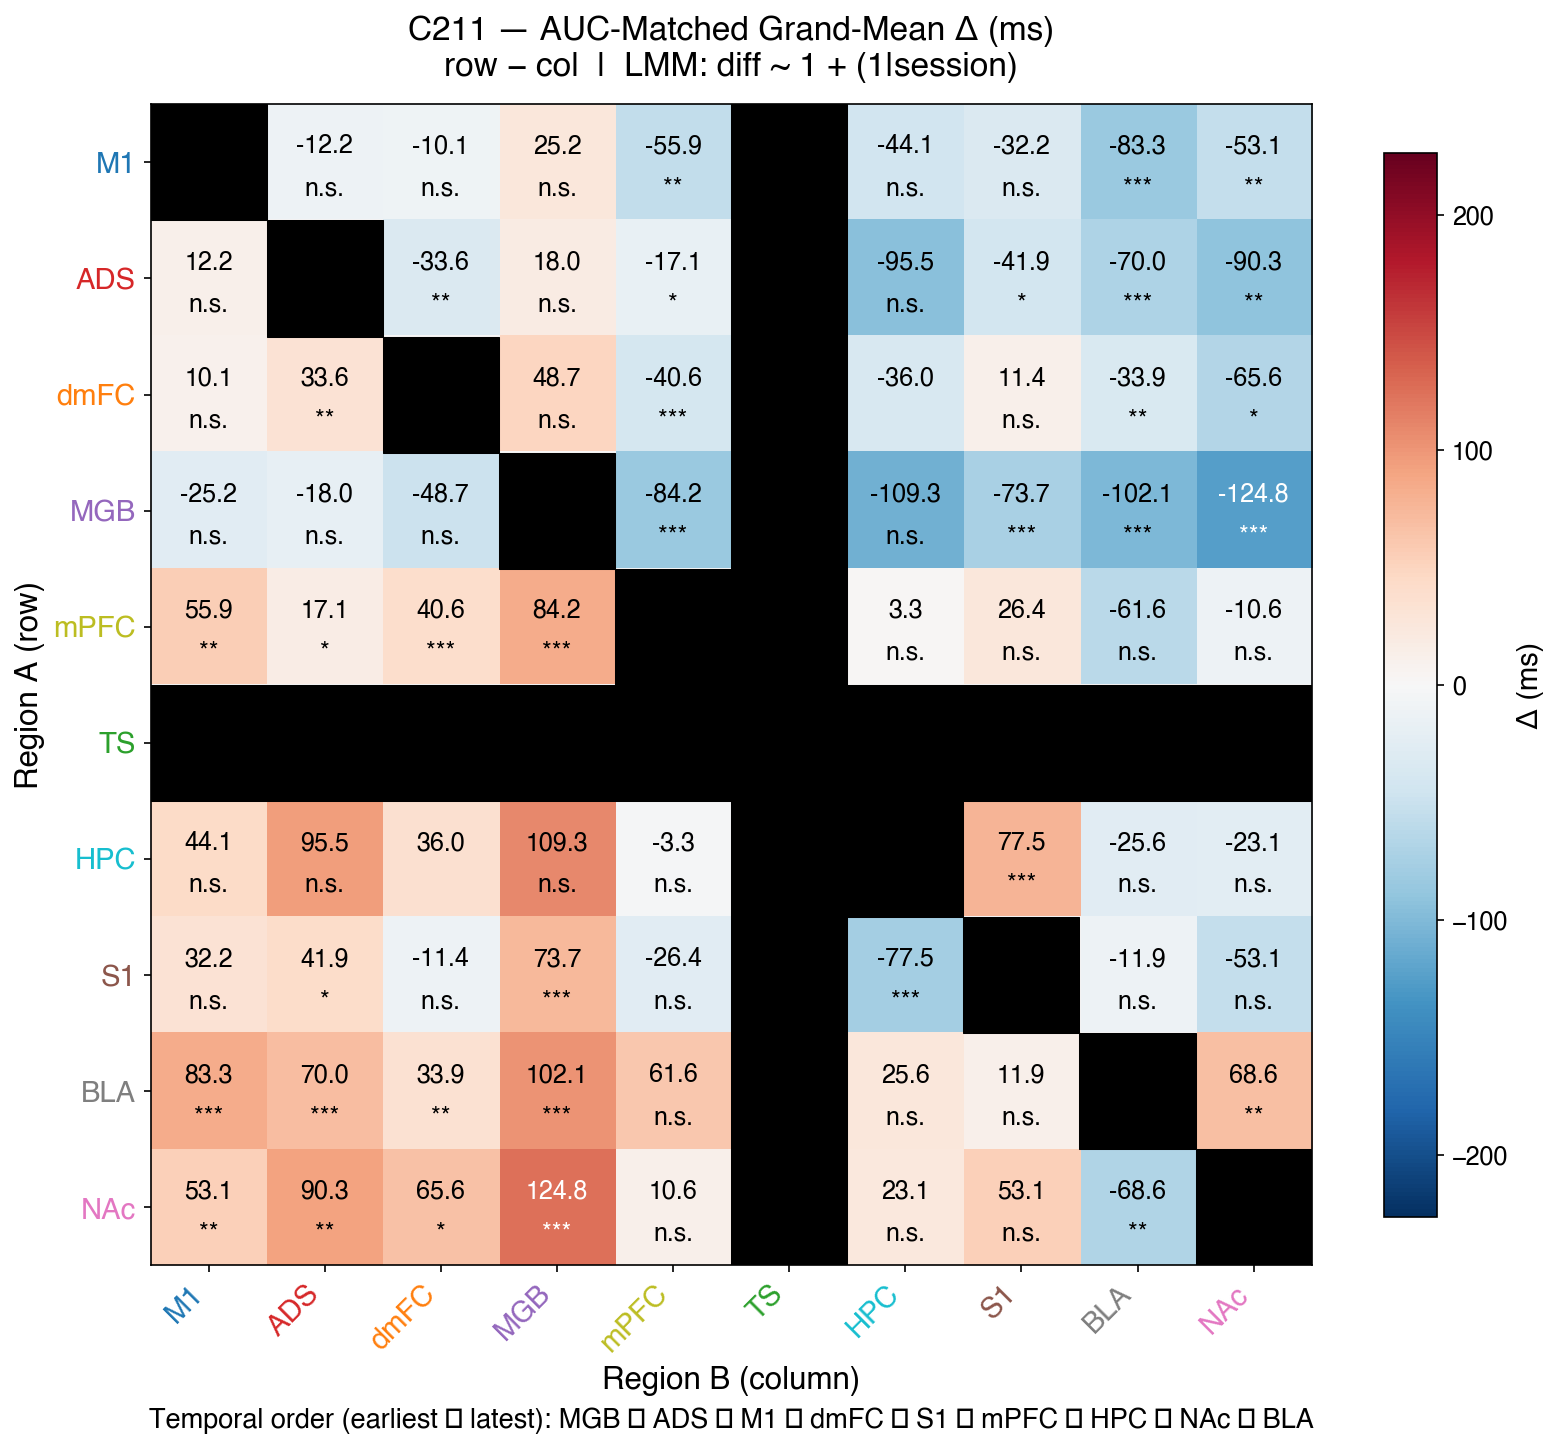

  C211 order: MGB → ADS → M1 → dmFC → S1 → mPFC → HPC → NAc → BLA


In [5]:
all_animal_stats = []

for animal in animals:
    avail = set(animal_regions[animal])
    n_reg = len(REGIONS)

    # Only compute pairs where both regions have data for this animal
    pairs = [(rA, rB) for rA, rB in combinations(REGIONS, 2)
             if rA in avail and rB in avail]

    mat_ms   = np.full((n_reg, n_reg), np.nan)
    has_data = np.zeros((n_reg, n_reg), dtype=bool)
    sig_mat  = [['' for _ in range(n_reg)] for _ in range(n_reg)]

    for rA, rB in pairs:
        gm, gsem, z_or_t, p_val, n_tr, method = pairwise_animal_stats(
            pair_data, animal, rA, rB
        )
        i, j = REGIONS.index(rA), REGIONS.index(rB)
        if not np.isnan(gm) and n_tr > 0:
            mat_ms[i, j] = gm * 1000
            mat_ms[j, i] = -gm * 1000
            has_data[i, j] = True
            has_data[j, i] = True
        label = _sig_label(p_val)
        sig_mat[i][j] = label
        sig_mat[j][i] = label

        all_animal_stats.append({
            'Animal': animal, 'Pair': f'{rA} \u2212 {rB}',
            'Grand \u0394 (ms)': f'{gm*1000:.1f}' if not np.isnan(gm) else 'n/a',
            'SEM (ms)': f'{gsem*1000:.1f}' if not np.isnan(gsem) else 'n/a',
            'n_trials': n_tr,
            'z/t': f'{z_or_t:.2f}' if not np.isnan(z_or_t) else 'n/a',
            'p': f'{p_val:.4f}' if not np.isnan(p_val) else 'n/a',
            'sig': label, 'test': method
        })

    # ---------- Plot ----------
    vmax = GLOBAL_VMAX
    display_mat = np.where(np.isnan(mat_ms), 0, mat_ms)

    fig, ax = plt.subplots(figsize=(max(8, n_reg * 1.1), max(7, n_reg * 1.0)))
    im = ax.imshow(display_mat, cmap='RdBu_r', vmin=-vmax, vmax=vmax, aspect='equal')

    # Black out diagonal and missing-data cells
    for i in range(n_reg):
        for j in range(n_reg):
            if i == j or not has_data[i, j]:
                ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1,
                             facecolor='black', edgecolor='black', linewidth=0.5))
            else:
                txt_color = 'white' if abs(mat_ms[i, j]) > vmax * 0.50 else 'black'
                ax.text(j, i - 0.14, f'{mat_ms[i, j]:.1f}',
                        ha='center', va='center', fontsize=12,
                        fontweight='bold', color=txt_color, fontfamily=_FONT_NAME)
                ax.text(j, i + 0.22, sig_mat[i][j],
                        ha='center', va='center', fontsize=12,
                        color=txt_color, fontfamily=_FONT_NAME)

    ax.set_xticks(range(n_reg))
    ax.set_yticks(range(n_reg))
    ax.set_xticklabels(REGIONS, fontsize=14, rotation=45, ha='right')
    ax.set_yticklabels(REGIONS, fontsize=14)
    color_ticklabels(ax, REGIONS)

    ax.set_xlabel('Region B (column)', fontsize=15, fontweight='bold', fontfamily=_FONT_NAME)
    ax.set_ylabel('Region A (row)', fontsize=15, fontweight='bold', fontfamily=_FONT_NAME)
    ax.set_title(f'{animal} \u2014 AUC-Matched Grand-Mean \u0394 (ms)\n'
                 f'row \u2212 col  |  LMM: diff ~ 1 + (1|session)',
                 fontsize=16, fontweight='bold', fontfamily=_FONT_NAME, pad=14)

    cbar = fig.colorbar(im, ax=ax, label='\u0394 (ms)', shrink=0.8)
    cbar.ax.tick_params(labelsize=12)
    cbar.set_label('\u0394 (ms)', fontsize=14, fontweight='bold', fontfamily=_FONT_NAME)

    # Temporal ordering (only regions with data)
    avail_indices = [i for i, r in enumerate(REGIONS) if r in avail]
    if len(avail_indices) >= 2:
        sub_means = [np.nanmean([mat_ms[i, j] for j in avail_indices if j != i])
                     for i in avail_indices]
        order = [avail_indices[k] for k in np.argsort(sub_means)]
        order_str = ' \u2192 '.join([REGIONS[i] for i in order])
        ax.text(0.5, -0.14, f'Temporal order (earliest \u2192 latest): {order_str}',
                transform=ax.transAxes, ha='center', fontsize=13,
                style='italic', fontfamily=_FONT_NAME)

    fig.tight_layout()
    fig.savefig(FIG_DIR / f'animal_heatmap_aucmatched_{animal}.svg',
                bbox_inches='tight', format='svg')
    plt.show()
    if len(avail_indices) >= 2:
        print(f'  {animal} order: {order_str}')


---
## 5 — Statistical Summary Table: Within-Animal LMM

In [6]:
stats_df = pd.DataFrame(all_animal_stats)
print('--- Within-Animal LMM Tests (AUC-Matched nTc) ---')
print('    Model: diff ~ 1 + (1 | session)   [REML]')
print('    H0: intercept = 0  (no mean timing difference)\n')
stats_df


--- Within-Animal LMM Tests (AUC-Matched nTc) ---
    Model: diff ~ 1 + (1 | session)   [REML]
    H0: intercept = 0  (no mean timing difference)



,Animal,Pair,Grand Δ (ms),SEM (ms),n_trials,z/t,p,sig,test
0,A324,M1 − ADS,-32.2,35.4,580,-0.86,0.3883,n.s.,LMM
1,A324,M1 − dmFC,-19.7,16.8,459,-1.42,0.1544,n.s.,LMM
2,A324,M1 − MGB,-42.1,42.4,444,-0.92,0.3581,n.s.,LMM
3,A324,M1 − mPFC,-26.5,14.9,265,-2.54,0.0110,*,LMM
4,A324,M1 − TS,-68.8,25.9,507,-2.66,0.0078,**,LMM
...,...,...,...,...,...,...,...,...,...
103,C211,HPC − BLA,-25.6,45.6,18,-0.89,0.3760,n.s.,LMM
104,C211,HPC − NAc,-23.1,18.1,11,-1.10,0.2707,n.s.,LMM
105,C211,S1 − BLA,-11.9,27.1,114,-0.93,0.3512,n.s.,LMM
106,C211,S1 − NAc,-53.1,26.8,136,-1.36,0.1734,n.s.,LMM


---
## 6 — Combined Across-Animal Heatmap

Each cell shows the **grand mean of per-animal means**: within each animal,
session-level means are averaged, then these per-animal estimates are averaged
across animals so that each animal contributes equally.
Same 10×10 layout; black cells for diagonal and missing pairs.


/var/folders/5k/pff9ts0j0jn2nmnnxqwrk_zr0000gq/T/ipykernel_77657/2827481738.py:71: UserWarning: Glyph 8594 (\N{RIGHTWARDS ARROW}) missing from font(s) Helvetica.
  fig.tight_layout()
/var/folders/5k/pff9ts0j0jn2nmnnxqwrk_zr0000gq/T/ipykernel_77657/2827481738.py:72: UserWarning: Glyph 8594 (\N{RIGHTWARDS ARROW}) missing from font(s) Helvetica.
  fig.savefig(FIG_DIR / 'combined_heatmap_aucmatched.svg',
/opt/miniconda3/envs/bl_pipeline_python_env/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8594 (\N{RIGHTWARDS ARROW}) missing from font(s) Helvetica.
  fig.canvas.print_figure(bytes_io, **kw)


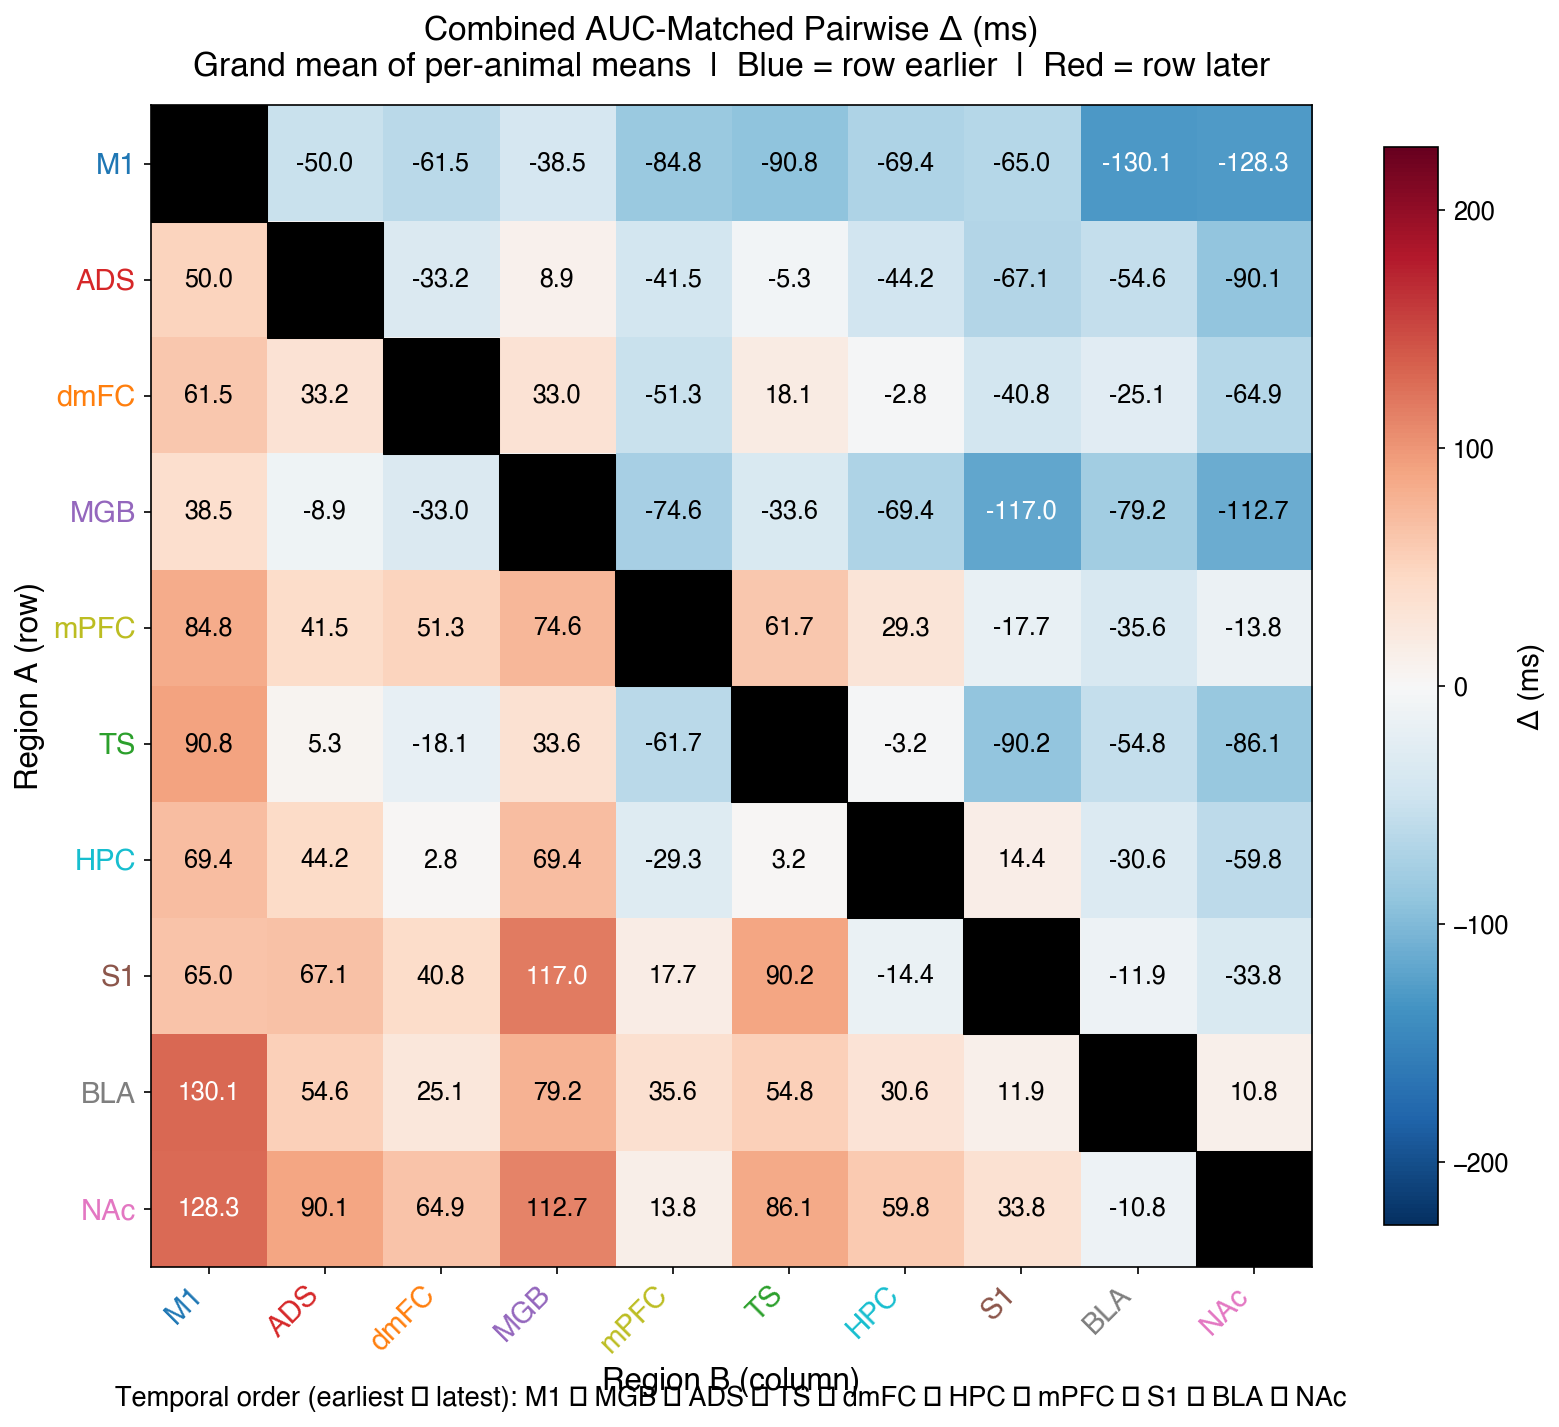

Combined temporal order: M1 → MGB → ADS → TS → dmFC → HPC → mPFC → S1 → BLA → NAc


In [7]:
n_reg = len(REGIONS)
comb_mat_ms   = np.full((n_reg, n_reg), np.nan)
comb_has_data = np.zeros((n_reg, n_reg), dtype=bool)

for rA, rB in combinations(REGIONS, 2):
    # Compute grand mean of per-animal means (each animal weighted equally)
    animal_means = []
    for animal in animals:
        sub = get_pair_diffs(pair_data, animal, rA, rB)
        if sub is not None and len(sub) > 0:
            sess_means = sub.groupby('recording_id')['diff'].mean()
            animal_means.append(sess_means.mean())

    if not animal_means:
        continue

    gm = np.mean(animal_means)
    i, j = REGIONS.index(rA), REGIONS.index(rB)

    if not np.isnan(gm):
        comb_mat_ms[i, j] = gm * 1000
        comb_mat_ms[j, i] = -gm * 1000
        comb_has_data[i, j] = True
        comb_has_data[j, i] = True

# ---------- Plot ----------
vmax = GLOBAL_VMAX
display_comb = np.where(np.isnan(comb_mat_ms), 0, comb_mat_ms)

fig, ax = plt.subplots(figsize=(max(10, n_reg * 1.1), max(9, n_reg * 1.0)))
im = ax.imshow(display_comb, cmap='RdBu_r', vmin=-vmax, vmax=vmax, aspect='equal')

for i in range(n_reg):
    for j in range(n_reg):
        if i == j or not comb_has_data[i, j]:
            ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1,
                         facecolor='black', edgecolor='black', linewidth=0.5))
        else:
            txt_color = 'white' if abs(comb_mat_ms[i, j]) > vmax * 0.50 else 'black'
            ax.text(j, i, f'{comb_mat_ms[i, j]:.1f}',
                    ha='center', va='center', fontsize=12,
                    fontweight='bold', color=txt_color, fontfamily=_FONT_NAME)

ax.set_xticks(range(n_reg))
ax.set_yticks(range(n_reg))
ax.set_xticklabels(REGIONS, fontsize=14, rotation=45, ha='right')
ax.set_yticklabels(REGIONS, fontsize=14)
color_ticklabels(ax, REGIONS)

ax.set_xlabel('Region B (column)', fontsize=15, fontweight='bold', fontfamily=_FONT_NAME)
ax.set_ylabel('Region A (row)', fontsize=15, fontweight='bold', fontfamily=_FONT_NAME)
ax.set_title('Combined AUC-Matched Pairwise \u0394 (ms)\n'
             'Grand mean of per-animal means  |  Blue = row earlier  |  Red = row later',
             fontsize=16, fontweight='bold', fontfamily=_FONT_NAME, pad=14)

cbar = fig.colorbar(im, ax=ax, label='\u0394 (ms)', shrink=0.8)
cbar.ax.tick_params(labelsize=12)
cbar.set_label('\u0394 (ms)', fontsize=14, fontweight='bold', fontfamily=_FONT_NAME)

# Temporal ordering (only regions with data)
avail_idx = [i for i in range(n_reg) if comb_has_data[i, :].any()]
if len(avail_idx) >= 2:
    sub_means = [np.nanmean([comb_mat_ms[i, j] for j in avail_idx if j != i])
                 for i in avail_idx]
    order = [avail_idx[k] for k in np.argsort(sub_means)]
    order_str = ' \u2192 '.join([REGIONS[i] for i in order])
    ax.text(0.5, -0.12, f'Temporal order (earliest \u2192 latest): {order_str}',
            transform=ax.transAxes, ha='center', fontsize=13,
            style='italic', fontfamily=_FONT_NAME)

fig.tight_layout()
fig.savefig(FIG_DIR / 'combined_heatmap_aucmatched.svg',
            bbox_inches='tight', format='svg')
plt.show()
if len(avail_idx) >= 2:
    print(f'Combined temporal order: {order_str}')


---
## 7 — Export Statistics

In [8]:
stats_df.to_csv(FIG_DIR / 'within_animal_stats_aucmatched.csv', index=False)
print(f'Saved: {FIG_DIR}/within_animal_stats_aucmatched.csv')
print('\n\u2713 Analysis complete.')


Saved: figures_pairwise_aucmatched/within_animal_stats_aucmatched.csv

✓ Analysis complete.
